# Regressão Linear

Base de dados utilizada:
1. Carregamento de dados
2. Análise dos dados
2. Remoção de campo desnecessário (b)
4. Tratamento de dados nulos e/ou faltantes
5. Separação dos dados, holdout
6. Normalização dos dados
7. Treinamento de modelos



**Integrantes:** Mauro Roberto Barbosa Cahu, Pedro Paulo Sant'Anna Belo Ramos, Renato Vasconcellos Bittencourt Neto e Vinicius Dantas Batista da Silva  

In [ ]:
# Regressão Linear, k-NN e Polinomial — Boston Housing Dataset

**Objetivo Geral da Atividade:**
Prever o preço mediano de casas nos subúrbios de Boston (variável alvo **`medv`**, expressa em milhares de dólares — ex.: `24.0` equivale a **US$ 24.000**) a partir de características socioeconômicas, urbanísticas e ambientais dos bairros. Trata-se de um problema clássico de **regressão supervisionada** (saída numérica contínua, e não de classificação), no qual comparamos três famílias de modelos preditivos:
1. **Regressão Linear Múltipla (`LinearRegression`)**
2. **k-Nearest Neighbors Regressor (`KNeighborsRegressor`)**
3. **Regressão Polinomial (`PolynomialFeatures` + `LinearRegression` de graus 1, 5 e 10)**

## Obtenha os dados
** Leia o arquivo csv 'BostonHousing.csv' em um DataFrame **

**Descrição dos dados**

O conjunto de dados Boston tem 506 linhas e 14 colunas.

Este conjunto de dados contém as seguintes colunas:

* crim: índice de criminalidade per capita por município.

* zn: proporção de terreno residencial zoneada para lotes acima de 25.000 metros quadrados.

* indus: proporção de hectares de negócios não varejistas por cidade.

* chas: Variável fictícia Charles River (= 1 se o trecho limita o rio; 0 caso contrário).

* nox: concentração de óxidos de nitrogênio (partes por 10 milhões).

* rm: número médio de cômodos por domicílio.

* idade / age: proporção de unidades ocupadas pelo proprietário construídas antes de 1940.

* dis: média ponderada das distâncias para cinco centros de emprego de Boston.

* rad: índice de acessibilidade às rodovias radiais.

* imposto / tax: valor total do imposto predial por \$10.000.

* ptratio: relação aluno-professor por município.

* **preto / b**: 1000(Bk - 0,63)^2 onde Bk é a proporção de negros por cidade.

* lstat: status inferior da população (porcentagem).

* medv: valor médio de residências ocupadas pelos proprietários em \$1000s. (**coluna target do nosso modelo**)

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv')

Verifique o cabeçalho do DataFrame

In [ ]:
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


Vamos remover a coluna b porque não vamos utilizar essa informação na nossa modelagem.

In [ ]:
### Descrição do Dataset e Remoção da Coluna `b`

O dataset original contém **506 linhas** (bairros/setores censitários de Boston) e **14 colunas**.

Removemos a coluna **`b`** (`df.drop(columns=['b'])`), que originalmente codificava uma proporção demográfica racial ($1000(B_k - 0{,}63)^2$). Essa remoção é uma **boa prática ética em Ciência de Dados moderna**, pois o uso dessa variável introduz viés racial na precificação imobiliária (motivo pelo qual o próprio `load_boston` foi descontinuado nas versões recentes do `scikit-learn`).

Após a remoção, restam **13 colunas**: **12 variáveis preditoras (`X`)** e **1 variável alvo (`y = medv`)**:
- `crim`: Taxa de criminalidade per capita por bairro
- `zn`: Proporção de terrenos residenciais zoneados para lotes acima de 25.000 sq.ft.
- `indus`: Proporção de acres comerciais não-varejistas por bairro
- `chas`: Variável dummy do Rio Charles (`1` se faz fronteira com o rio; `0` caso contrário)
- `nox`: Concentração de óxidos nítricos (partes por 10 milhões)
- `rm`: Número médio de quartos (cômodos) por habitação
- `age`: Proporção de unidades ocupadas pelos proprietários construídas antes de 1940
- `dis`: Distância ponderada até cinco centros de emprego de Boston
- `rad`: Índice de acessibilidade a rodovias radiais
- `tax`: Taxa de imposto predial sobre propriedade de valor total por US$ 10.000
- `ptratio`: Proporção aluno-professor por bairro
- `lstat`: Percentual da população considerada de menor status socioeconômico
- **`medv` (Alvo / Target)**: Valor mediano das residências ocupadas pelos proprietários em **US$ 1.000**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  lstat    506 non-null    float64
 12  medv     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


In [ ]:
df.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


### Análise Exploratória de Dados (EDA): Valores Nulos e Escalas das Variáveis

1. **Verificação de Dados Faltantes (`isna().sum()`):** Todas as colunas apresentam **zero valores nulos**, portanto não há necessidade de imputação ou descarte de registros.
2. **Análise de Escalas e Outliers (Boxplot):** O gráfico de caixa com todas as variáveis na mesma escala revela **grandes discrepâncias de grandeza**:
   - `tax` varia de **187 a 711** e `age` chega a **100**;
   - `nox` varia apenas entre **0,38 e 0,87** e `chas` é binária (**0 ou 1**);
   - Há forte presença de *outliers* em `crim` (bairros com criminalidade extrema) e `zn`.
   - **Por que isso importa?** Modelos baseados em distância (como o **k-NN**) seriam completamente dominados pelas variáveis de maior valor numérico (`tax` e `age`), ignorando variáveis críticas de menor escala (`nox`, `rm`). Isso justifica a etapa de **padronização (`StandardScaler`)** a seguir.

Dados faltantes

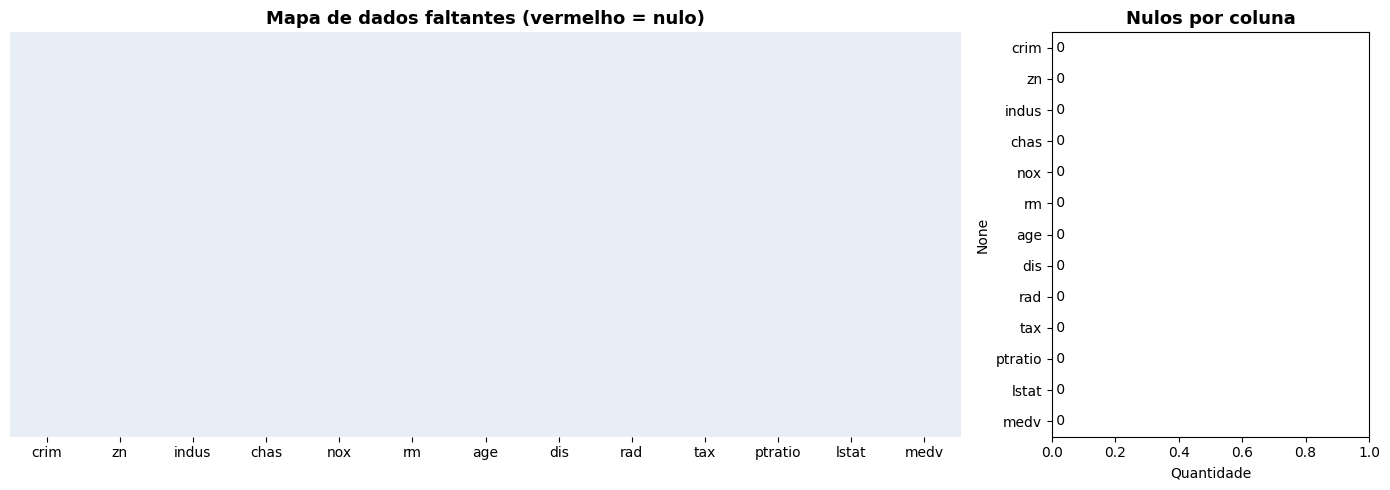

In [ ]:
nulos = df.isnull().sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [3, 1]})

# mapa de nulos (amarelo = faltante, cinza claro = presente)
sns.heatmap(df.isnull(), cbar=False, yticklabels=False,
            cmap=['#e8eef5', '#e63946'], ax=axes[0])
axes[0].set_title('Mapa de dados faltantes (vermelho = nulo)', fontsize=13, weight='bold')

# contagem por coluna
sns.barplot(x=nulos.values, y=nulos.index, color='#2a9d8f', ax=axes[1])
axes[1].set_title('Nulos por coluna', fontsize=13, weight='bold')
axes[1].set_xlabel('Quantidade')
axes[1].set_xlim(0, max(1, nulos.max()))
for i, v in enumerate(nulos.values):
    axes[1].text(v, i, f' {v}', va='center')

plt.tight_layout()
plt.show()

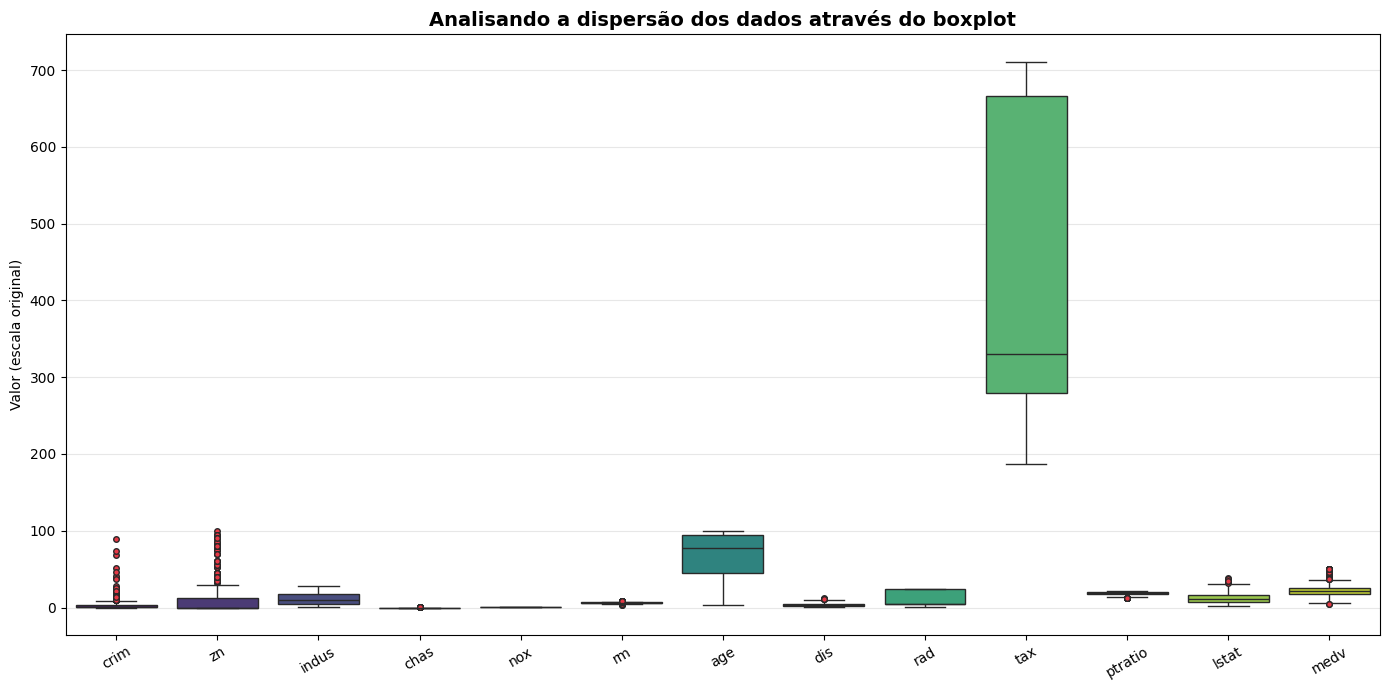

In [ ]:
plt.figure(figsize=(14, 7))
sns.boxplot(data=df, palette='viridis',
            flierprops=dict(marker='o', markerfacecolor='#e63946', markersize=4))
plt.title('Analisando a dispersão dos dados através do boxplot', fontsize=14, weight='bold')
plt.ylabel('Valor (escala original)')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Nota-se a necessidade de normalização dos dadeos vistoque a coluna de tax está muito fora do padrão das demais.

## Separação dos dados, holdout

Use o método train_test_split para dividir seus dados em um conjunto treino e teste.

A coluna target do nosso modelo é **medv**

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
### Divisão Treino e Teste (Holdout 70% / 30%)

- **`X`**: Matriz com as **12 variáveis explicativas** (`df.drop('medv', axis=1)`).
- **`y`**: Vetor com a variável resposta **`medv`**.
- **Divisão (`train_test_split`):**
  - **Treino (70%):** **354 imóveis** — usados para ensinar os padrões aos modelos e ajustar o normalizador.
  - **Teste (30%):** **152 imóveis** — guardados como dados inéditos para avaliar a capacidade real de generalização.
  - **`random_state=111`:** Fixa a semente pseudoaleatória para garantir total reprodutibilidade dos resultados.

In [ ]:
pd.DataFrame(X_train).head(5)

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat
199,0.03150,95.0,1.47,0,0.403,6.975,15.3,7.6534,3,402,17.0,4.56
101,0.11432,0.0,8.56,0,0.520,6.781,71.3,2.8561,5,384,20.9,7.67
386,24.39380,0.0,18.10,0,0.700,4.652,100.0,1.4672,24,666,20.2,28.28
77,0.08707,0.0,12.83,0,0.437,6.140,45.8,4.0905,5,398,18.7,10.27
176,0.07022,0.0,4.05,0,0.510,6.020,47.2,3.5549,5,296,16.6,10.11


In [ ]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(354, 12) (152, 12) (354,) (152,)


Nota-se que está sem a coluna medv que será a usada para o modelo. As outras colunas serão usadas para treiná-lo

## Normalização dos dados

Vamos normalizar os dados.

Import StandardScaler do Scikit-learn.

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
### Padronização (`StandardScaler`) sem Vazamento de Dados (*Data Leakage*)

O `StandardScaler` transforma cada variável para que tenha **média $\mu = 0$** e **desvio-padrão $\sigma = 1$** segundo a fórmula:

$$z = \frac{x - \mu_{\text{treino}}}{\sigma_{\text{treino}}}$$

**Regra de Ouro aplicada no código:**
- Usamos **`scaler.fit_transform(X_train)`** no treino (calcula média e desvio-padrão **apenas** das 354 amostras de treino e transforma).
- Usamos **`scaler.transform(X_test)`** no teste (aplica a média e o desvio do treino sobre os 152 imóveis de teste).
- Se fizéssemos `fit` no conjunto de teste, cometeríamos **vazamento de dados (*data leakage*)**, passando informações estatísticas do futuro/teste para o treinamento.

Converta as variáveis independentes com o StandardScaler

In [ ]:
scaler.fit(X_train)

StandardScaler()

Use o método .transform () para transformar os parâmetros em uma versão padronizada.

In [ ]:
**Verificação pós-normalização:**
Observando as estatísticas descritivas (`describe()`) após a padronização:
- Em `X_train_scaled`, todas as variáveis têm **`mean = 0.00`** e **`std = 1.00`**.
- Em `X_test_scaled`, as médias ficam **próximas de zero** (ex.: `-0.08`, `-0.06`, `0.09`) e os desvios próximos de 1, mas não exatamente 0 e 1, comprovando que o teste foi transformado com os parâmetros aprendidos exclusivamente no treino.

In [ ]:
X_train_scaled[:3]

array([[-0.44907456,  3.78381385, -1.43347391, -0.28154625, -1.33889353,
         1.02600682, -1.97141772,  1.85891086, -0.76927921, -0.07524679,
        -0.75662273, -1.19006285],
       [-0.43799762, -0.46194571, -0.40276632, -0.28154625, -0.31222266,
         0.73462462,  0.06573687, -0.42852307, -0.54062695, -0.18141874,
         1.10972235, -0.74008473],
       [ 2.80931263, -0.46194571,  0.98410962, -0.28154625,  1.26727098,
        -2.46306977,  1.10977861, -1.09077412,  1.63156951,  1.48194185,
         0.77473734,  2.24192461]])

In [ ]:
import numpy as np
print(np.round(X_train_scaled.mean(axis=0), 3))   # ~0 em todas
print(np.round(X_train_scaled.std(axis=0), 3))    # ~1 em todas
print(np.round(X_test_scaled.mean(axis=0), 2))    # próximo de 0, mas não exato

[-0. -0.  0.  0.  0.  0. -0.  0. -0. -0.  0.  0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
[ 0.1   0.15 -0.09 -0.05 -0.03 -0.04 -0.11  0.06 -0.07 -0.13 -0.2  -0.06]


No treino sai 0 e 1 exatos. No teste fica próximo, mas não exato: é o esperado, prova que o teste foi tratado como dado novo.

Visualizando os dados de treinamento.

In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 354 entries, 199 to 340
Data columns (total 12 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     354 non-null    float64
 1   zn       354 non-null    float64
 2   indus    354 non-null    float64
 3   chas     354 non-null    int64  
 4   nox      354 non-null    float64
 5   rm       354 non-null    float64
 6   age      354 non-null    float64
 7   dis      354 non-null    float64
 8   rad      354 non-null    int64  
 9   tax      354 non-null    int64  
 10  ptratio  354 non-null    float64
 11  lstat    354 non-null    float64
dtypes: float64(9), int64(3)
memory usage: 36.0 KB


Visualizando os dados de teste.

In [ ]:
X_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 152 entries, 93 to 158
Data columns (total 12 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     152 non-null    float64
 1   zn       152 non-null    float64
 2   indus    152 non-null    float64
 3   chas     152 non-null    int64  
 4   nox      152 non-null    float64
 5   rm       152 non-null    float64
 6   age      152 non-null    float64
 7   dis      152 non-null    float64
 8   rad      152 non-null    int64  
 9   tax      152 non-null    int64  
 10  ptratio  152 non-null    float64
 11  lstat    152 non-null    float64
dtypes: float64(9), int64(3)
memory usage: 15.4 KB


## Regressão Linear

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
reg = LinearRegression()
reg.fit(X_train_scaled, y_train)

LinearRegression()

**Executar o modelo treinado na base de treinamento**

In [ ]:
y_train_pred = reg.predict(X_train_scaled)
y_test_pred = reg.predict(X_test_scaled)

Analisando o score de treino e teste.

In [ ]:
reg.score(X_train_scaled, y_train)   # treino

0.7381975510401046

In [ ]:
reg.score(X_test_scaled, y_test)     # teste

0.711547915567693

**Análise do Score ($R^2$) — Regressão Linear:**
- **$R^2$ Treino:** `0,7382` (73,82% da variância explicada)
- **$R^2$ Teste:** `0,7115` (71,15% da variância explicada)

A diferença entre treino e teste é muito pequena (**~2,67 pontos percentuais**), demonstrando que a Regressão Linear **não sofre de *overfitting*** (ela generaliza de forma consistente). Contudo, os ~29% de variância não explicada indicam que existem **relações não lineares** no mercado imobiliário de Boston que uma reta/hiperplano rígido não consegue capturar.

**Avaliação de Regressores - Exibir os Resultados**

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score

In [ ]:
def print_metrics(y_test_in, y_test_pred_in):
  print("MAE: ", mean_absolute_error(y_test_in, y_test_pred_in))
  print("MAPE: ", mean_absolute_percentage_error(y_test_in, y_test_pred_in))
  print("MSE: ", mean_squared_error(y_test_in, y_test_pred_in))
  print("RMSE: ", mean_squared_error(y_test_in, y_test_pred_in)**2)
  print("R²: ", r2_score(y_test_in, y_test_pred_in))

In [ ]:
# dados de treino
print_metrics(y_train, y_train_pred)

MAE:  3.1835585717761252
MAPE:  0.16078737073033178
MSE:  20.374619886830068
RMSE:  415.12513553281127
R²:  0.7381975510401046


In [ ]:
# dados de teste
print_metrics(y_test, y_test_pred)

MAE:  3.701488287606292
MAPE:  0.17831885665559696
MSE:  28.607656840343854
RMSE:  818.3980298948725
R²:  0.711547915567693


**Interpretação detalhada das métricas da Regressão Linear:**

| Conjunto | MAE (US$ mil) | MAPE | MSE | $\text{RMSE} = \sqrt{\text{MSE}}$ (US$ mil) | Saída `MSE**2` do código | $R^2$ |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Treino (70%)** | 3,18 | 16,08% | 20,37 | **4,51** | 415,13 | **0,7382** |
| **Teste (30%)** | 3,70 | 17,83% | 28,61 | **5,35** | 818,40 | **0,7115** |

- **MAE (Erro Médio Absoluto = 3,70 no teste):** Em média, o modelo erra cerca de **US$ 3.700** no preço de cada casa.
- **MAPE (Erro Percentual Absoluto Médio = 0,1783):** O erro médio equivale a **17,83%** do valor real do imóvel.
- **MSE (Erro Quadrático Médio = 28,61):** Eleva os erros ao quadrado, penalizando severamente erros grandes.
- **Nota Técnica sobre o RMSE na função `print_metrics`:** Na função definida acima, a linha do RMSE foi escrita como `MSE**2` (MSE elevado ao quadrado = `818,40`), quando matematicamente o **RMSE (*Root Mean Squared Error*)** é a **raiz quadrada do MSE** (`np.sqrt(MSE)` = **5,35**, ou seja, ~US$ 5.350 na mesma escala do alvo `medv`).

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

In [ ]:
knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

KNeighborsRegressor(n_neighbors=3)

No k-NN regressor, a previsão de um imóvel é a média do medv dos k vizinhos mais próximos (distância euclidiana). Ele não aprende coeficientes, apenas guarda o treino. Por isso a normalização é essencial aqui: sem ela, tax dominaria a distância.

**Executar o modelo treinado na base de treinamento**

In [ ]:
y_train_knn_pred = knn.predict(X_train_scaled)
y_test_knn_pred = knn.predict(X_test_scaled)

In [ ]:
# score dos dados de treino
knn.score(X_train_scaled, y_train)

0.8670591164466853

In [ ]:
# score dos dados de teste.
knn.score(X_test_scaled, y_test)

0.7597083113180875

**Análise do k-NN com $K = 3$:**
- **$R^2$ Treino:** `0,8671` (86,71%)
- **$R^2$ Teste:** `0,7597` (75,97%)

A diferença entre treino e teste subiu para **10,74 pontos percentuais** (bem maior que os 2,67 pontos da Regressão Linear), sinalizando um grau moderado de **overfitting** típico de valores pequenos de $K$. Em compensação, o **$R^2$ de teste (0,760) supera o da Regressão Linear (0,712)**, confirmando que o k-NN captura **padrões não lineares locais** (imóveis com perfil socioeconômico semelhante tendem a ter preços semelhantes).

**Avaliar o melhor valor de K**

k= 1
k= 2
k= 3
k= 4
k= 5
k= 6
k= 7
k= 8
k= 9
k= 10
k= 11
k= 12
k= 13
k= 14
k= 15
k= 16
k= 17
k= 18
k= 19
k= 20
k= 21
k= 22
k= 23
k= 24
k= 25
k= 26
k= 27
k= 28
k= 29


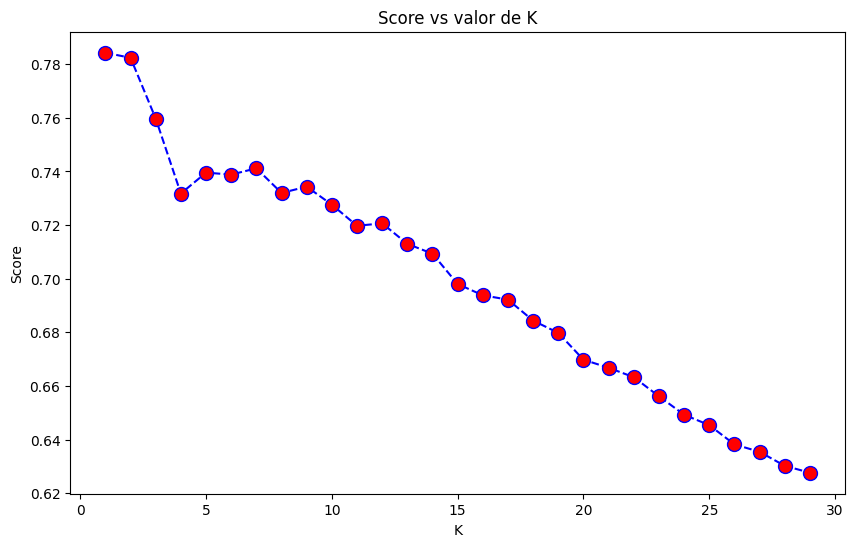

In [ ]:
import numpy as np

score = []

for i in range(1, 30):
    ## treine o modelo
    knn_i = KNeighborsRegressor(n_neighbors=i)
    knn_i.fit(X_train_scaled, y_train)
    ## calcule as métricas
    s = knn_i.score(X_test_scaled, y_test)
    ## armazene na lista score
    score.append(s)
    print("k=", i)

plt.figure(figsize=(10,6))
plt.plot(range(1,30), score, color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Score vs valor de K')
plt.xlabel('K')
plt.ylabel('Score')
plt.show()

**Escolha do Melhor $K$ ($K=1$ a $K=29$):**
O gráfico mostra que o maior $R^2$ no conjunto de teste ocorre em **$K = 1$ ($R^2 = 0,7843$)**, caindo gradualmente à medida que $K$ aumenta (pois considerar vizinhos demais dilui a média com bairros menos parecidos).

> **Observação Metodológica Importante:** Escolher o hiperparâmetro $K$ olhando diretamente para o desempenho no conjunto de teste pode tornar a estimativa levemente otimista. Em um pipeline produtivo rigoroso, a escolha de $K$ deve ser feita via **Validação Cruzada (`GridSearchCV` / `cross_val_score`)** apenas dentro do conjunto de treino.

In [ ]:
melhor_k = score.index(max(score)) + 1
print("Melhor k:", melhor_k, "| R² teste:", round(max(score), 4))

Melhor k: 1 | R² teste: 0.7843


### Criar um regressor com o melhor valor para o melhor K e avaliar





In [ ]:
## com o melhor valor de k
melhor_k = score.index(max(score)) + 1
print("Melhor k:", melhor_k)

knn = KNeighborsRegressor(n_neighbors=melhor_k)
knn.fit(X_train_scaled, y_train)

y_train_knn_pred = knn.predict(X_train_scaled)
y_test_knn_pred = knn.predict(X_test_scaled)

print(knn.score(X_train_scaled, y_train))
print(knn.score(X_test_scaled, y_test))

Melhor k: 1
1.0
0.7842753969841532


**Análise do k-NN com $K = 1$ (Treino vs. Teste):**
- **Por que o Treino deu $R^2 = 1,0$ e Erro Zero (`MAE = 0.0`, `MSE = 0.0`)?**
  Com $K = 1$, para prever o preço de uma casa do conjunto de treino, o algoritmo busca a 1 casa mais próxima no próprio treino — que é **ela mesma** (distância zero!). Logo, o modelo **memoriza 100% do treino** (overfitting máximo no treino).
- **Desempenho no Teste ($R^2 = 0,7843$, `MAE = 3,13`):**
  Mesmo memorizando o treino, no conjunto de teste inédito o $K = 1$ obteve o melhor resultado geral da atividade: erra em média **US$ 3.132 por imóvel** (`MAE = 3,13`), com **MAPE de 15,44%** e **RMSE real de $\sqrt{21,39} = 4,63$ (~US$ 4.625)**.

**Avaliação de Regressores - k-NN**

In [ ]:
print("Dados de treino")
print_metrics(y_train, y_train_knn_pred)

Dados de treino
MAE:  0.0
MAPE:  0.0
MSE:  0.0
RMSE:  0.0
R²:  1.0


In [ ]:
print("Dados de teste")
print_metrics(y_test, y_test_knn_pred)

Dados de teste
MAE:  3.132236842105263
MAPE:  0.15442199439994692
MSE:  21.394802631578948
RMSE:  457.7375796442175
R²:  0.7842753969841532


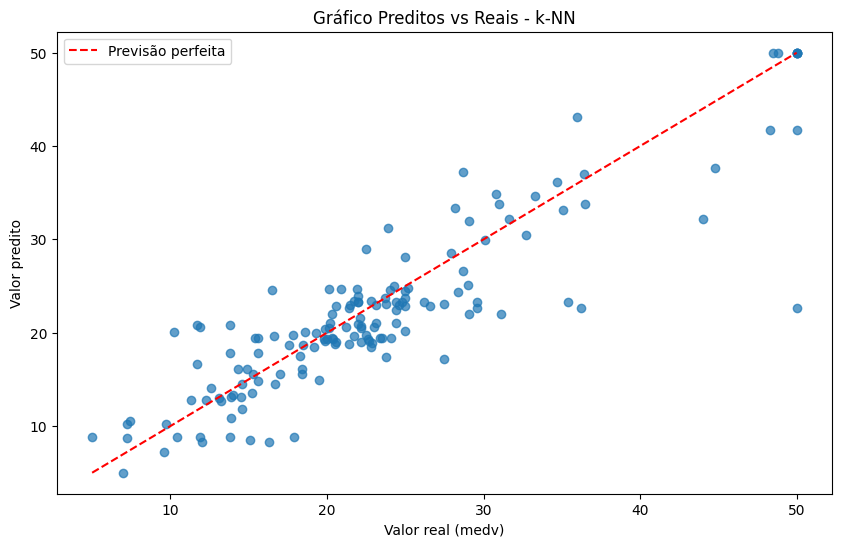

In [ ]:
plt.figure(figsize=(10,6))
plt.title('Gráfico Preditos vs Reais - k-NN')
plt.scatter(y_test, y_test_knn_pred, alpha=0.7)
plt.plot([5, 50], [5, 50], 'r--', label='Previsão perfeita')
plt.xlabel('Valor real (medv)')
plt.ylabel('Valor predito')
plt.legend()
plt.show()

## Treinar o modelo de Regressão Polinomial, n=1, n=5, n=10

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

### Transformação Polinomial (`PolynomialFeatures` — Graus 1, 5 e 10) e Explosão Combinatória

A Regressão Polinomial cria novas colunas elevando as variáveis originais a potências ($x_1^2, x_1^3, \dots$) e multiplicando-as entre si (termos de interação $x_1 \cdot x_2$, etc.), aplicando em seguida uma `LinearRegression` sobre essas colunas expandidas.

Como temos $d = 12$ variáveis preditoras, o número de colunas geradas pelo grau $g$ segue a combinação $\binom{d + g}{g}$:
- **Grau 1:** `(354, 13)` $\rightarrow$ 1 coluna de intercepto (*bias*) + 12 variáveis originais.
- **Grau 5:** `(354, 6188)` $\rightarrow$ **6.188 variáveis** para apenas **354 imóveis** de treino!
- **Grau 10:** `(354, 646646)` $\rightarrow$ **646.646 variáveis** para apenas **354 imóveis** de treino!
- *(Nota: O Grau 15 geraria $\binom{27}{15} = 17.678.835$ colunas, sendo computacionalmente inviável em memória RAM).*

Grau 1

In [ ]:
poly_grau_1 = PolynomialFeatures(degree=1)
X_train_scaled_poly_1 = poly_grau_1.fit_transform(X_train_scaled)
X_test_scaled_poly_1 = poly_grau_1.transform(X_test_scaled)

print(X_train_scaled_poly_1.shape)

(354, 13)


Grau 5

In [ ]:
poly_grau_5 = PolynomialFeatures(degree=5)
X_train_scaled_poly_5 = poly_grau_5.fit_transform(X_train_scaled)
X_test_scaled_poly_5 = poly_grau_5.transform(X_test_scaled)

print(X_train_scaled_poly_5.shape)

(354, 6188)


Grau 10

In [ ]:
poly_grau_10 = PolynomialFeatures(degree=10)
X_train_scaled_poly_10 = poly_grau_10.fit_transform(X_train_scaled)
X_test_scaled_poly_10 = poly_grau_10.transform(X_test_scaled)

print(X_train_scaled_poly_10.shape)

(354, 646646)


**Treinar o modelo de regressão linear para verificar o melhor resultado da transformação polinomial**

Grau 1

In [ ]:
## treine o modelo
reg_poly_1 = LinearRegression()
reg_poly_1.fit(X_train_scaled_poly_1, y_train)
y_pred_poly_1 = reg_poly_1.predict(X_test_scaled_poly_1)

In [ ]:
## analise as métricas
print_metrics(y_test, y_pred_poly_1)

MAE:  3.7014882876062947
MAPE:  0.17831885665559713
MSE:  28.60765684034387
RMSE:  818.3980298948735
R²:  0.7115479155676928


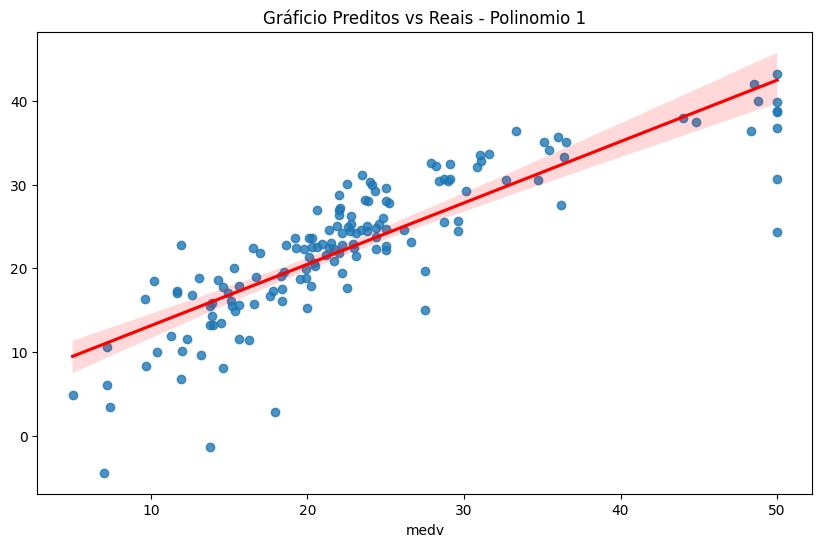

In [ ]:
plt.figure(figsize=(10,6))
plt.title('Gráficio Preditos vs Reais - Polinomio 1')
sns.regplot(x=y_test,y=y_pred_poly_1,line_kws={"color": "red"})
plt.show()

Grau 5

In [ ]:
## treine o modelo
reg_poly_5 = LinearRegression()
reg_poly_5.fit(X_train_scaled_poly_5, y_train)
y_pred_poly_5 = reg_poly_5.predict(X_test_scaled_poly_5)


In [ ]:
## análise as métricas
print_metrics(y_test, y_pred_poly_5)

MAE:  111.86301225378274
MAPE:  10.490816949028153
MSE:  1107844.024351937
RMSE:  1227318382292.2952
R²:  -11169.433140806323


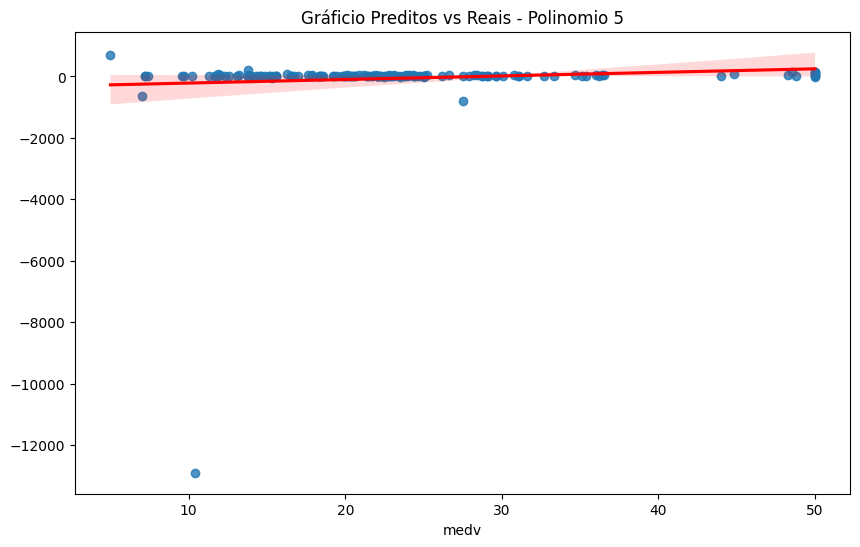

In [ ]:
plt.figure(figsize=(10,6))
plt.title('Gráficio Preditos vs Reais - Polinomio 5')
sns.regplot(x=y_test,y=y_pred_poly_5,line_kws={"color": "red"})
plt.show()

Grau 10

In [ ]:
## treine o modelo - vai demorar um pouco..
reg_poly_10 = LinearRegression()
reg_poly_10.fit(X_train_scaled_poly_10, y_train)
y_pred_poly_10 = reg_poly_10.predict(X_test_scaled_poly_10)


In [ ]:
## analise as métricas
print_metrics(y_test, y_pred_poly_10)

MAE:  61310.04824702118
MAPE:  6040.642738535281
MSE:  534457952687.77765
RMSE:  2.8564530319121077e+23
R²:  -5388959722.42626


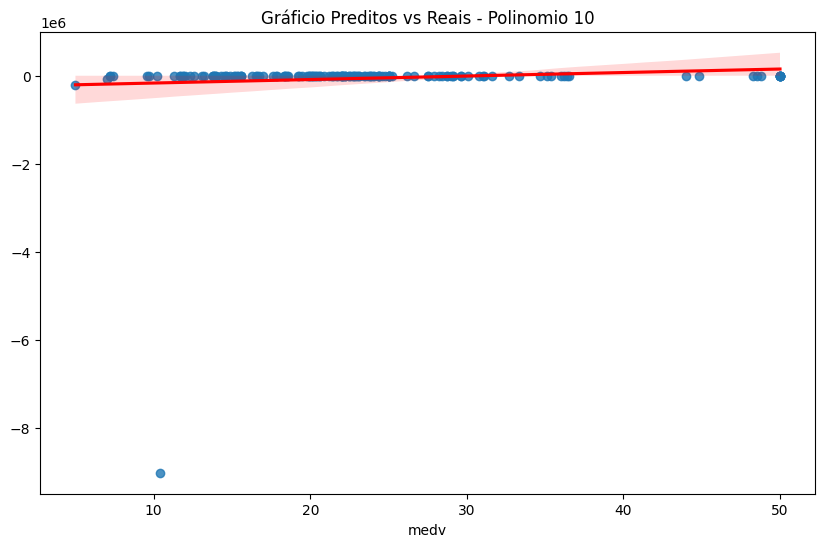

In [ ]:
plt.figure(figsize=(10,6))
plt.title('Gráficio Preditos vs Reais - Polinomio 10')
sns.regplot(x=y_test,y=y_pred_poly_10,line_kws={"color": "red"})
plt.show()

## Conclusão Geral e Diagnóstico Técnico

Neste estudo, utilizamos o dataset **Boston Housing** (506 registros, 12 variáveis preditoras após remoção ética da coluna `b`, e variável alvo `medv`) para comparar três abordagens de regressão. O dataset não possui valores faltantes (`isna().sum() = 0`). O boxplot inicial evidenciou escalas drasticamente distintas (`tax` até 711 vs. `nox` abaixo de 0,9), justificando a padronização com `StandardScaler` ajustado exclusivamente no conjunto de treino (Holdout 70% = 354 imóveis / 30% = 152 imóveis, `random_state=111`) para evitar *data leakage*.

### Tabela Comparativa de Desempenho

| Modelo | Atributos ($p$) | $R^2$ Treino | $R^2$ Teste | MAE Teste (US$ mil) | MAPE Teste | MSE Teste | $\text{RMSE} = \sqrt{\text{MSE}}$ | Diagnóstico |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **Regressão Linear** | 12 | 0,7382 | 0,7115 | 3,70 | 17,83% | 28,61 | 5,35 | **Estável / Sem Overfitting** (não captura não-linearidades) |
| **k-NN ($K = 3$)** | 12 | 0,8671 | 0,7597 | — | — | — | — | **Bom ajuste não-linear** (leve overfitting: gap de 10,7 pts) |
| **k-NN ($K = 1$)** | 12 | 1,0000 | **0,7843** | **3,13** | **15,44%** | **21,39** | **4,63** | **Melhor $R^2$ no teste** (memoriza o treino por construção) |
| **Polinomial Grau 1** | 13 | 0,7382 | 0,7115 | 3,70 | 17,83% | 28,61 | 5,35 | **Idêntico à Regressão Linear** (serve como controle) |
| **Polinomial Grau 5** | 6.188 | 1,0000 | -11.169,43 | 111,86 | 1.049,08% | $1,11 \times 10^6$ | 1.052,54 | **Colapso por Overfitting** ($p = 6.188 \gg n = 354$) |
| **Polinomial Grau 10** | 646.646 | 1,0000 | $-5,39 \times 10^9$ | 61.310,05 | 604.064% | $5,34 \times 10^{11}$ | 731.066,31 | **Explosão Combinatória Extrema** ($p = 646.646 \gg n = 354$) |

### Principais Aprendizados (Trade-off Viés-Variância)
1. **Regressão Linear (Alto Viés, Baixa Variância):** Apresentou comportamento muito estável ($R^2$ de 0,738 no treino e 0,712 no teste, MAE de US$ 3,70 mil). Não sofre de *overfitting*, mas é limitada por assumir relações estritamente lineares.
2. **k-NN Regressor (Não-Paramétrico Baseado em Distância):** Superou a Regressão Linear no teste ($R^2 = 0,760$ com $K=3$ e $R^2 = 0,784$ com $K=1$), provando que existem **não-linearidades importantes** nos dados imobiliários. Com $K=1$, o $R^2$ de treino é 1,0 por construção (cada ponto é seu próprio vizinho mais próximo), mas ainda assim obteve o menor erro no teste (MAE = US$ 3,13 mil). Ressalta-se que a seleção de $K$ deve idealmente utilizar **Validação Cruzada** no treino para não enviesar a escolha pelo teste.
3. **Regressão Polinomial e a Maldição da Dimensionalidade (Baixo Viés, Altíssima Variância):** Enquanto o Grau 1 reproduz exatamente a Regressão Linear, os Graus 5 (6.188 colunas) e 10 (646.646 colunas) têm **muito mais variáveis do que exemplos de treino ($p \gg n = 354$)**. A curva polinomial passa exatamente pelos pontos de treino (decorando o ruído), mas oscila violentamente fora deles, gerando previsões absurdas no teste e $R^2$ fortemente negativo (pior do que simplesmente chutar a média).